In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

TOP_K = 3

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")

print("Movies dataset:")
display(movies.head())

print("Ratings dataset:")
display(ratings.head())

Movies dataset:


,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


Ratings dataset:


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


1. What does one row in movies represent?
checks for one movie which is identified by movie_id with its title and genres.
2. What does one row in ratings represent?
Checks for one user's rating of a movie
3. How many unique users and movies are present?
12 unique users and 20 unique movies
4. What type of feedback is the rating column?
Explicit feedback since the users directly provide numerical ratings
5. What is the rating scale?
observed ratings ranges from 2 to 5


In [3]:
print("Number of unique users:", ratings["user_id"].nunique())
print("Number of unique movies in ratings:", ratings["movie_id"].nunique())
print("Total rating records:", len(ratings))

print("\nMovies dataset columns:")
print(movies.columns.tolist())

print("\nRatings dataset columns:")
print(ratings.columns.tolist())

Number of unique users: 12
Number of unique movies in ratings: 20
Total rating records: 120

Movies dataset columns:
['movie_id', 'title', 'genres']

Ratings dataset columns:
['user_id', 'movie_id', 'rating', 'timestamp']


In [4]:
print("Missing values in movies:")
display(movies.isnull().sum())

print("\nMissing values in ratings:")
display(ratings.isnull().sum())

print("\nDuplicate rows in movies:", movies.duplicated().sum())
print("Duplicate user-movie pairs:",
      ratings.duplicated(subset=["user_id", "movie_id"]).sum())

print("\nRating range:")
print("Minimum rating:", ratings["rating"].min())
print("Maximum rating:", ratings["rating"].max())

Missing values in movies:


,0
movie_id,0
title,0
genres,0



Missing values in ratings:


,0
user_id,0
movie_id,0
rating,0
timestamp,0



Duplicate rows in movies: 0
Duplicate user-movie pairs: 0

Rating range:
Minimum rating: 2
Maximum rating: 5


Rating distribution:


,count
rating,
2,29
3,49
4,28
5,14



Rating proportions (%):


,count
rating,
2,24.17
3,40.83
4,23.33
5,11.67


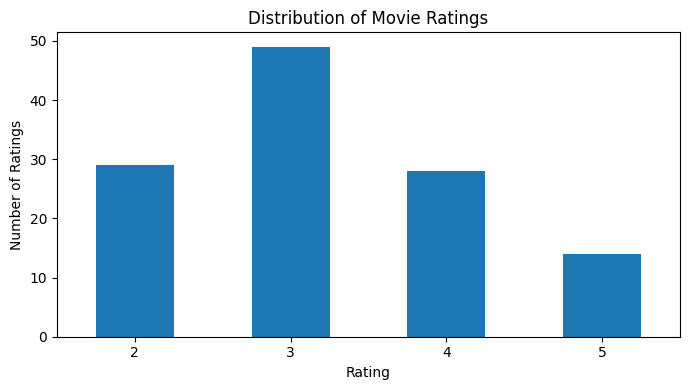

Mean rating: 3.22
Median rating: 3.0
Most common rating: [3]
Ratings of 4 or 5: 42
Percentage rated 4 or 5: 35.0 %


In [5]:
rating_counts = ratings["rating"].value_counts().sort_index()

print("Rating distribution:")
display(rating_counts)

print("\nRating proportions (%):")
display((rating_counts / len(ratings) * 100).round(2))


plt.figure(figsize=(7, 4))

rating_counts.plot(kind="bar")

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


print("Mean rating:", round(ratings["rating"].mean(), 2))
print("Median rating:", ratings["rating"].median())
print("Most common rating:", ratings["rating"].mode().tolist())
print("Ratings of 4 or 5:",
      (ratings["rating"] >= 4).sum())
print("Percentage rated 4 or 5:",
      round((ratings["rating"] >= 4).mean() * 100, 2), "%")


The rating distribution of 3 is the most common. This accounts for 40.83% of all ratings, followed by ratings of 2 at 24.17%, ratings of 4 at 23.33%, and ratings of 5 at 11.67%.

Overall, moderate and lower ratings 2 and 3 account for 65% of the data, while higher ratings 4 and 5 account for 35%, indicating that users tend to give moderate rather than highly positive ratings.

This distribution may affect recommender evaluation as models must distinguish genuinely relevant movies from those receiving moderate ratings.

In [6]:
ratings = ratings.sort_values(["user_id", "timestamp"])

test = ratings.groupby("user_id").tail(1).copy()

train = ratings.drop(test.index).copy()

print("Total interactions:", len(ratings))
print("Training interactions:", len(train))
print("Test interactions:", len(test))

print("\nTest records:")
display(test.head())

print("\nTraining records by user:")
display(train.groupby("user_id").size())

print("\nTest records by user:")
display(test.groupby("user_id").size())


Total interactions: 120
Training interactions: 108
Test interactions: 12

Test records:


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50



Training records by user:


,0
user_id,
1,9
2,9
3,9
4,9
5,9
6,9
7,9
8,9
9,9



Test records by user:


,0
user_id,
1,1
2,1
3,1
4,1
5,1
6,1
7,1
8,1
9,1


In [7]:
print("One test record per user:",
      test.groupby("user_id").size().eq(1).all())

train_pairs = set(zip(train["user_id"], train["movie_id"]))
test_pairs = set(zip(test["user_id"], test["movie_id"]))

print("No user-movie overlap:",
      train_pairs.isdisjoint(test_pairs))

print("Users in training:", train["user_id"].nunique())
print("Users in testing:", test["user_id"].nunique())

One test record per user: True
No user-movie overlap: True
Users in training: 12
Users in testing: 12


The train/test split prevents the recommender from being evaluated on the same interactions used to build the model.

The most recent interaction for each user is reserved for testing, while earlier interactions are used for training. This provides a more realistic assessment of how well the recommender predicts unseen user preferences.

In [8]:
global_mean = train["rating"].mean()

movie_stats = (
    train.groupby("movie_id")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
    .merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )
)

movie_stats = movie_stats.sort_values(
    ["mean_rating", "rating_count"],
    ascending=[False, False]
)

print("Global training mean:", round(global_mean, 3))
print("\nTop 10 movies by baseline ranking:")
display(movie_stats.head(10))

Global training mean: 3.222

Top 10 movies by baseline ranking:


,movie_id,mean_rating,rating_count,title
5,6,4.166667,6,Broken Hearts
0,1,4.000000,3,Galaxy Mission
17,18,4.000000,2,The Promise
3,4,3.800000,5,Family Weekend
9,10,3.666667,6,Hidden Truth
15,16,3.571429,7,Campus Life
6,7,3.500000,8,City Detectives
12,13,3.400000,5,Digital Dreams
18,19,3.250000,4,Night Chase
2,3,3.166667,6,Final Battle


In [9]:
movie_mean_map = (
    train.groupby("movie_id")["rating"]
    .mean()
    .to_dict()
)

baseline_test = test.copy()

baseline_test["prediction"] = (
    baseline_test["movie_id"].map(movie_mean_map)
)

baseline_test["prediction"] = (
    baseline_test["prediction"].fillna(global_mean)
)

display(
    baseline_test[
        ["user_id", "movie_id", "rating", "prediction"]
    ].head(10)
)


,user_id,movie_id,rating,prediction
9,1,14,4,2.857143
19,2,9,4,3.000000
29,3,18,3,4.000000
39,4,18,3,4.000000
49,5,11,2,2.500000
59,6,2,5,3.100000
69,7,3,2,3.166667
79,8,12,2,3.000000
89,9,16,2,3.571429
99,10,19,3,3.250000


In [10]:
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))


Baseline MAE: 1.086
Baseline RMSE: 1.201


The popularity baseline provides a simple benchmark, but its MAE and RMSE indicate that movie-average ratings do not always accurately predict individual users' preferences.

In [11]:
genre_features = movies["genres"].str.get_dummies(sep="|")

content_items = pd.concat(
    [movies[["movie_id", "title"]], genre_features],
    axis=1
)

genre_columns = genre_features.columns.tolist()

item_feature_matrix = content_items.set_index("movie_id")[genre_columns]

print("Number of movies:", len(item_feature_matrix))
print("Number of genre features:", len(genre_columns))

print("\nAvailable genres:")
print(genre_columns)

print("\nMovie feature matrix:")
display(content_items.head(10))

Number of movies: 20
Number of genre features: 9

Available genres:
['Action', 'Adventure', 'Comedy', 'Crime', 'Drama', 'Family', 'Mystery', 'Romance', 'Sci-Fi']

Movie feature matrix:


,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1
5,6,Broken Hearts,0,0,0,0,1,0,0,1,0
6,7,City Detectives,0,0,0,1,1,0,0,0,0
7,8,Space Warriors,1,0,0,0,0,0,0,0,1
8,9,Wedding Weekend,0,0,1,0,0,0,0,1,0
9,10,Hidden Truth,0,0,0,0,1,0,1,0,0


In [12]:
print("Feature matrix shape:", item_feature_matrix.shape)

print("\nFirst five movies:")
display(item_feature_matrix.head())

print("\nCheck that genre values are binary:")
print(
    item_feature_matrix.isin([0, 1]).all().all()
)

Feature matrix shape: (20, 9)

First five movies:


,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
movie_id,,,,,,,,,
1,1,0,0,0,0,0,0,0,1
2,0,0,0,0,1,0,0,1,0
3,1,0,0,0,0,0,0,0,0
4,0,0,1,0,0,1,0,0,0
5,1,0,0,0,0,0,0,0,1



Check that genre values are binary:
True


In [13]:
def build_user_profile(user_id, train_data):
    history = train_data[
        train_data["user_id"] == user_id
    ]

    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)

    features = item_feature_matrix.loc[ids].values

    return (features * ratings_array).mean(axis=0)


profile = build_user_profile(1, train)

profile_summary = pd.Series(
    profile,
    index=genre_columns
).sort_values(ascending=False)

print("User 1's genre preference profile:")
display(profile_summary)


User 1's genre preference profile:


,0
Drama,1.666667
Sci-Fi,1.000000
Comedy,0.888889
Romance,0.666667
Action,0.555556
Family,0.555556
Crime,0.333333
Mystery,0.333333
Adventure,0.222222


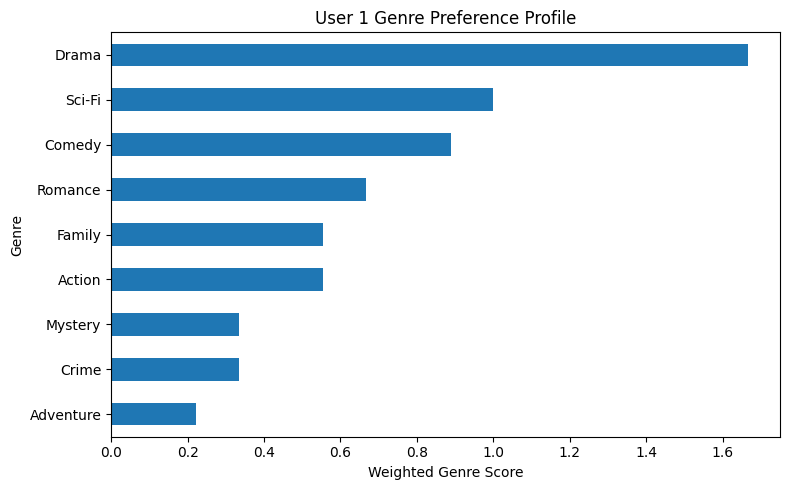

In [14]:
profile_summary.sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    title="User 1 Genre Preference Profile"
)

plt.xlabel("Weighted Genre Score")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


In [15]:
def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]

    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)

    features = item_feature_matrix.loc[ids].values

    return (features * ratings_array).mean(axis=0)


profile = build_user_profile(1, train)

profile_summary = pd.Series(
    profile,
    index=genre_columns
).sort_values(ascending=False)

display(profile_summary)

,0
Drama,1.666667
Sci-Fi,1.000000
Comedy,0.888889
Romance,0.666667
Action,0.555556
Family,0.555556
Crime,0.333333
Mystery,0.333333
Adventure,0.222222


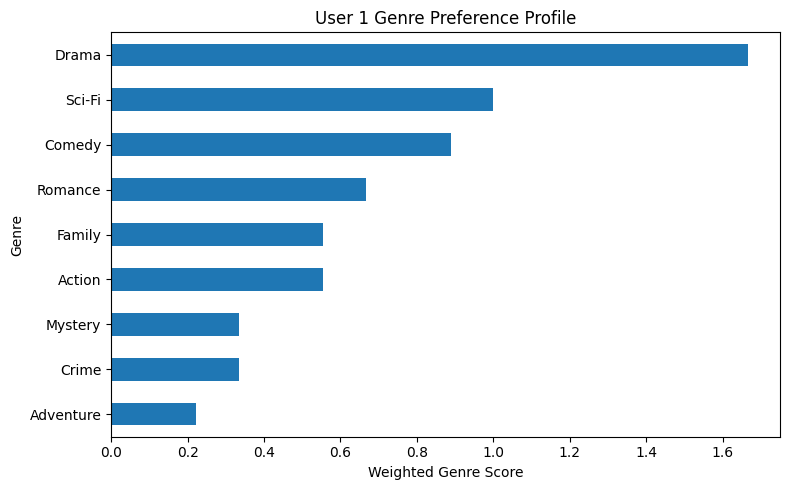

In [16]:
profile_summary.sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    title="User 1 Genre Preference Profile"
)

plt.xlabel("Weighted Genre Score")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

In [17]:
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)

    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)

    sim = cosine_similarity(profile, item_vec)[0, 0]

    return float(np.clip(1 + 4 * sim, 1, 5))


content_test = test.copy()

content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train),
    axis=1
)

content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)

print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


MAE: The content-based model's MAE of 1.094 is slightly higher than the baseline's 1.086.

This means its predictions are marginally less accurate on average.



RMSE: Its RMSE of 1.381 is higher than the baseline's 1.20
This indicates larger prediction errors under this metric, which penalizes large errors more heavily.


Based on these rating-prediction metrics, the popularity baseline currently performs better than the content-based model.

In [18]:
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

print("User-item matrix shape:", user_item.shape)
print("Item-user matrix shape:", item_user.shape)
print("Item similarity matrix shape:", item_similarity.shape)

display(item_similarity.iloc[:5, :5])

User-item matrix shape: (12, 20)
Item-user matrix shape: (20, 12)
Item similarity matrix shape: (20, 20)


movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


In [19]:
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

print("User-item matrix shape:", user_item.shape)
print("Item-user matrix shape:", item_user.shape)
print("Item similarity matrix shape:", item_similarity.shape)

def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["user_id"] == user_id]

    weighted_sum = 0.0
    similarity_sum = 0.0

    for _, row in history.iterrows():
        rated_movie = row["movie_id"]

        if rated_movie not in item_similarity.columns:
            continue

        sim = item_similarity.loc[movie_id, rated_movie]

        if sim > 0:
            weighted_sum += sim * row["rating"]
            similarity_sum += sim

    if similarity_sum == 0:
        return float(global_mean)

    return float(weighted_sum / similarity_sum)


cf_test = test.copy()

cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(
        r["user_id"], r["movie_id"], train
    ),
    axis=1
)

cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)

print("Item-CF MAE:", round(cf_mae, 3))
print("Item-CF RMSE:", round(cf_rmse, 3))

User-item matrix shape: (12, 20)
Item-user matrix shape: (20, 12)
Item similarity matrix shape: (20, 20)
Item-CF MAE: 0.924
Item-CF RMSE: 1.07


In [20]:
rating_comparison = pd.DataFrame({
    "Model": [
        "Popularity Baseline",
        "Content-Based",
        "Item-Based Collaborative Filtering"
    ],
    "MAE": [
        baseline_mae,
        content_mae,
        cf_mae
    ],
    "RMSE": [
        baseline_rmse,
        content_rmse,
        cf_rmse
    ]
})

display(
    rating_comparison.round(3).sort_values("RMSE")
)

,Model,MAE,RMSE
2,Item-Based Collaborative Filtering,0.924,1.070
0,Popularity Baseline,1.086,1.201
1,Content-Based,1.094,1.381


Which model has the lowest MAE?
item based collaborative filtering
Which model has the lowest RMSE?
item based colaborative filtering
Does either advanced model clearly beat the baseline?
popularity baseline performed slightly better than content-based filtering
Why should you avoid declaring a model best from only one metric?
reducing model biasness before evaluating other different models

In [21]:
RELEVANCE_THRESHOLD = 4

test_relevant = test.copy()
test_relevant["relevant"] = (
    test_relevant["rating"] >= RELEVANCE_THRESHOLD
)

print("Total test interactions:", len(test_relevant))
print("Relevant test interactions:", test_relevant["relevant"].sum())
print(
    "Relevant proportion:",
    round(test_relevant["relevant"].mean(), 3)
)

display(test_relevant.head(10))

Total test interactions: 12
Relevant test interactions: 5
Relevant proportion: 0.417


,user_id,movie_id,rating,timestamp,relevant
9,1,14,4,10,True
19,2,9,4,20,True
29,3,18,3,30,False
39,4,18,3,40,False
49,5,11,2,50,False
59,6,2,5,60,True
69,7,3,2,70,False
79,8,12,2,80,False
89,9,16,2,90,False
99,10,19,3,100,False


In [22]:
def recommend_top_n(user_id, model, n=3):
    seen_movies = set(
        train.loc[train["user_id"] == user_id, "movie_id"]
    )

    candidates = movies[
        ~movies["movie_id"].isin(seen_movies)
    ].copy()

    if model == "popularity":
        candidates["score"] = candidates["movie_id"].map(
            movie_mean_map
        ).fillna(global_mean)

    elif model == "content":
        candidates["score"] = candidates["movie_id"].apply(
            lambda movie_id: content_score(
                user_id, movie_id, train
            )
        )

    elif model == "item_cf":
        candidates["score"] = candidates["movie_id"].apply(
            lambda movie_id: item_cf_predict(
                user_id, movie_id, train
            )
        )

    else:
        raise ValueError("Unknown model name")

    return candidates.sort_values(
        "score", ascending=False
    ).head(n)[["movie_id", "title", "score"]]


for model_name in ["popularity", "content", "item_cf"]:
    print(f"\n{model_name.upper()} recommendations for User 1:")
    display(recommend_top_n(1, model_name, n=3))


POPULARITY recommendations for User 1:


,movie_id,title,score
5,6,Broken Hearts,4.166667
17,18,The Promise,4.000000
15,16,Campus Life,3.571429



CONTENT recommendations for User 1:


,movie_id,title,score
15,16,Campus Life,3.975493
17,18,The Promise,3.716754
5,6,Broken Hearts,3.716754



ITEM_CF recommendations for User 1:


,movie_id,title,score
11,12,The Last Case,3.237060
10,11,Laugh Out Loud,3.152937
17,18,The Promise,3.121372


In [23]:
import numpy as np
import pandas as pd

RELEVANCE_THRESHOLD = 4
K = 3

relevant_by_user = (
    test[test["rating"] >= RELEVANCE_THRESHOLD]
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)


def precision_at_k(recommended, relevant, k=3):
    top_k = recommended[:k]
    hits = sum(movie_id in relevant for movie_id in top_k)
    return hits / k


def recall_at_k(recommended, relevant, k=3):
    if len(relevant) == 0:
        return np.nan

    top_k = recommended[:k]
    hits = sum(movie_id in relevant for movie_id in top_k)
    return hits / len(relevant)


def ndcg_at_k(recommended, relevant, k=3):
    top_k = recommended[:k]

    gains = [
        1 if movie_id in relevant else 0
        for movie_id in top_k
    ]

    dcg = sum(
        gain / np.log2(rank + 2)
        for rank, gain in enumerate(gains)
    )

    ideal_gains = sorted(gains, reverse=True)
    idcg = sum(
        gain / np.log2(rank + 2)
        for rank, gain in enumerate(ideal_gains)
    )

    return dcg / idcg if idcg > 0 else 0.0


evaluation_rows = []

for model_name in ["popularity", "content", "item_cf"]:
    for user_id in sorted(test["user_id"].unique()):
        recommendations = recommend_top_n(
            user_id, model_name, n=K
        )

        recommended_ids = recommendations["movie_id"].tolist()
        relevant_ids = relevant_by_user.get(user_id, set())

        evaluation_rows.append({
            "user_id": user_id,
            "model": model_name,
            "Precision@3": precision_at_k(
                recommended_ids, relevant_ids, K
            ),
            "Recall@3": recall_at_k(
                recommended_ids, relevant_ids, K
            ),
            "NDCG@3": ndcg_at_k(
                recommended_ids, relevant_ids, K
            )
        })


ranking_results = pd.DataFrame(evaluation_rows)

print("Per-user ranking metrics:")
display(ranking_results.round(3))

print("Average ranking metrics by model:")
ranking_summary = (
    ranking_results
    .groupby("model")[
        ["Precision@3", "Recall@3", "NDCG@3"]
    ]
    .mean()
    .reset_index()
)

display(ranking_summary.round(3))

Per-user ranking metrics:


,user_id,model,Precision@3,Recall@3,NDCG@3
0,1,popularity,0.000,0.0,0.0
1,2,popularity,0.000,0.0,0.0
2,3,popularity,0.000,NaN,0.0
3,4,popularity,0.000,NaN,0.0
4,5,popularity,0.000,NaN,0.0
5,6,popularity,0.000,0.0,0.0
6,7,popularity,0.000,NaN,0.0
7,8,popularity,0.000,NaN,0.0
8,9,popularity,0.000,NaN,0.0
9,10,popularity,0.000,NaN,0.0


Average ranking metrics by model:


,model,Precision@3,Recall@3,NDCG@3
0,content,0.028,0.2,0.083
1,item_cf,0.000,0.0,0.000
2,popularity,0.028,0.2,0.042


In [24]:
catalogue_size = movies["movie_id"].nunique()

coverage_results = []

for model_name in ["popularity", "content", "item_cf"]:
    recommended_movies = set()

    for user_id in sorted(test["user_id"].unique()):
        recommendations = recommend_top_n(
            user_id, model_name, n=3
        )

        recommended_movies.update(
            recommendations["movie_id"].tolist()
        )

    coverage = len(recommended_movies) / catalogue_size

    coverage_results.append({
        "model": model_name,
        "unique_movies_recommended": len(recommended_movies),
        "catalogue_size": catalogue_size,
        "catalogue_coverage": coverage
    })

coverage_summary = pd.DataFrame(coverage_results)

display(coverage_summary.round(3))

,model,unique_movies_recommended,catalogue_size,catalogue_coverage
0,popularity,7,20,0.35
1,content,14,20,0.70
2,item_cf,17,20,0.85


In [25]:
import numpy as np
import pandas as pd

movie_popularity = train["movie_id"].value_counts()

total_train_ratings = len(train)

novelty_results = []

for model_name in ["popularity", "content", "item_cf"]:
    user_novelty_scores = []

    for user_id in sorted(test["user_id"].unique()):
        recommendations = recommend_top_n(
            user_id, model_name, n=3
        )

        for movie_id in recommendations["movie_id"]:
            count = movie_popularity.get(movie_id, 0)

            probability = (count + 1) / (
                total_train_ratings + len(movies)
            )

            novelty = -np.log2(probability)
            user_novelty_scores.append(novelty)

    novelty_results.append({
        "model": model_name,
        "average_novelty": np.mean(user_novelty_scores)
    })

novelty_summary = pd.DataFrame(novelty_results)

display(novelty_summary.round(3))

,model,average_novelty
0,popularity,4.733
1,content,4.453
2,item_cf,4.720


In [26]:
from sklearn.metrics.pairwise import cosine_similarity

def recommendation_diversity(recommendations):
    movie_ids = recommendations["movie_id"].tolist()

    if len(movie_ids) < 2:
        return 0.0

    feature_matrix = item_feature_matrix.loc[movie_ids].values
    similarity_matrix = cosine_similarity(feature_matrix)

    distances = []

    for i in range(len(movie_ids)):
        for j in range(i + 1, len(movie_ids)):
            distances.append(
                1 - similarity_matrix[i, j]
            )

    return float(np.mean(distances))


diversity_results = []

for model_name in ["popularity", "content", "item_cf"]:
    user_diversity_scores = []

    for user_id in sorted(test["user_id"].unique()):
        recommendations = recommend_top_n(
            user_id, model_name, n=3
        )

        score = recommendation_diversity(recommendations)
        user_diversity_scores.append(score)

    diversity_results.append({
        "model": model_name,
        "average_diversity": np.mean(user_diversity_scores)
    })

diversity_summary = pd.DataFrame(diversity_results)

display(diversity_summary.round(3))

,model,average_diversity
0,popularity,0.736
1,content,0.542
2,item_cf,0.780


In [27]:
final_evaluation = pd.DataFrame({
    "model": ["popularity", "content", "item_cf"],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})

final_evaluation = final_evaluation.merge(
    ranking_summary, on="model", how="left"
)

final_evaluation = final_evaluation.merge(
    coverage_summary[["model", "catalogue_coverage"]],
    on="model", how="left"
)

final_evaluation = final_evaluation.merge(
    novelty_summary, on="model", how="left"
)

final_evaluation = final_evaluation.merge(
    diversity_summary, on="model", how="left"
)

display(final_evaluation.round(3))

,model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,catalogue_coverage,average_novelty,average_diversity
0,popularity,1.086,1.201,0.028,0.2,0.042,0.35,4.733,0.736
1,content,1.094,1.381,0.028,0.2,0.083,0.70,4.453,0.542
2,item_cf,0.924,1.070,0.000,0.0,0.000,0.85,4.720,0.780


Best rating prediction

Item-based CF, with MAE 0.924 and RMSE 1.070.



Best ranking quality

Content-based filtering, with the highest NDCG@3 of 0.083.



Highest catalogue coverage

Item-based CF, at 85%.



Highest novelty
Popularity, at 4.733.



Highest diversity

Item-based CF, at 0.780.

The best model for the business scenario
that allows the similar popular titles to dominate is content-based filtering as it has the best NDCG@3 and ties popularity on Precision@3 and Recall@3.



metrics that influenced my choice most were NDCG@3, catalogue coverage, and diversity.

Item-based collaborative filtering offers greater coverage and diversity, but its ranking metrics were zero in this evaluation.

The dataset is small

In [29]:
k_values = [1, 3, 5]
models = ["popularity", "content", "item_cf"]

results_k = []

for model_name in models:
    for k in k_values:
        precision_scores = []
        recall_scores = []

        for user_id in sorted(test["user_id"].unique()):
            recommendations = recommend_top_n(
                user_id, model_name, n=k
            )

            recommended_ids = recommendations["movie_id"].tolist()
            relevant_ids = relevant_by_user.get(user_id, set())

            precision_scores.append(
                precision_at_k(recommended_ids, relevant_ids, k)
            )

            recall_scores.append(
                recall_at_k(recommended_ids, relevant_ids, k)
            )

        results_k.append({
            "Model": model_name,
            "K": k,
            "Precision@K": np.mean(precision_scores),
            "Recall@K": np.nanmean(recall_scores)
        })

results_k_df = pd.DataFrame(results_k)

display(results_k_df.round(3))

,Model,K,Precision@K,Recall@K
0,popularity,1,0.000,0.0
1,popularity,3,0.028,0.2
2,popularity,5,0.017,0.2
3,content,1,0.083,0.2
4,content,3,0.028,0.2
5,content,5,0.033,0.4
6,item_cf,1,0.000,0.0
7,item_cf,3,0.000,0.0
8,item_cf,5,0.017,0.2


Content-based filtering at K = 5 offers the strongest recall in this experiment, while its precision remains low. The small dataset and limited test interactions mean these findings should be interpreted cautiously.

including additional movies does not guarantee improved precision